# Surface Tension of Liquid Alloys: Butler Equation

The Butler equation predicts the surface tension of a liquid alloy from the surface tensions of the pure liquids and the excess Gibbs energy of the bulk liquid. The surface is treated as a monolayer phase in equilibrium with the bulk, so that for every component $i$ of an $n$-component liquid

$$\sigma = \sigma_i + \frac{RT}{A_i} \ln\frac{x_i^S}{x_i^B} + \frac{1}{A_i}\left[\beta \, G_i^{E}(T, x^S) - G_i^{E}(T, x^B)\right]$$

where $x^B$ and $x^S$ are the bulk and surface compositions, $G_i^E$ is the partial excess Gibbs energy of $i$ in the bulk liquid, and $\sigma_i$ and $A_i = L N_A^{1/3} V_i^{2/3}$ are the surface tension and molar surface area of pure liquid $i$. Following [T. Tanaka, K. Hack, T. Iida, S. Hara, Z. Metallkd. 87 (1996) 380-389](https://hdl.handle.net/11094/26520), the excess Gibbs energy of the surface is $\beta = 0.83$ times that of the bulk at the same composition and $L = 1.091$ for liquid metals. The $n$ equations plus $\sum_i x_i^S = 1$ are solved for $\sigma$ and $x^S$.

Here $G_i^E$ comes from the COST 507 light alloys database (I. Ansara, A.T. Dinsdale, M.H. Rand (Eds.), COST 507: Thermochemical Database for Light Metal Alloys, Vol. 2, Luxembourg, 1998).

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import N_A, R
from scipy.optimize import root

import pycalphad.plot.triangular  # registers the 'triangular' projection
from pycalphad import Database, Workspace, variables as v

# COST 507 emits benign warnings at load about unused type-definition characters
warnings.filterwarnings('ignore', category=UserWarning, module='pycalphad.io.tdb')

## Pure element data

The pure liquids are described by $\sigma_i(T) = \sigma_{m,i} + \frac{d\sigma_i}{dT}(T - T_{m,i})$ and $V_i(T) = V_{m,i}\left[1 + \alpha_i (T - T_{m,i})\right]$. Surface tensions of Al and Cu are those used by Schmitz et al. (see below), Mg is from B.J. Keene, Int. Mater. Rev. 38 (1993) 157, and Si is from K.C. Mills, Y.C. Su, Int. Mater. Rev. 51 (2006) 329. Molar volumes and expansion coefficients are from T. Iida, R.I.L. Guthrie, The Physical Properties of Liquid Metals (1988).

In [2]:
#        sigma_m [N/m], dsigma/dT [N/m/K], T_m [K], V_m [m^3/mol], alpha [1/K]
PURE = {
    'AL': (0.871, -1.55e-4,  933, 11.3e-6, 1.5e-4),
    'CU': (1.300, -2.64e-4, 1358, 7.94e-6, 1.0e-4),
    'MG': (0.577, -2.60e-4,  923, 15.3e-6, 1.6e-4),
    'SI': (0.850, -2.50e-4, 1683, 11.1e-6, 1.4e-4),
}

## Butler surface tension as a computable property

Any object implementing pycalphad's `ComputableProperty` protocol (`implementation_units`, `display_units`, `shape` and `compute_property`) can be passed to `Workspace.get`. `ButlerSurfaceTension` finds the liquid composition set at each condition and solves the Butler equations for it.

For a substitutional (one-sublattice) liquid the partial excess Gibbs energies at any composition $y$ follow from the mixing Gibbs energy `GM_MIX` and its gradient, both available from the composition set's compiled `PhaseRecord`:

$$G_i^E = G^{mix} + \frac{\partial G^{mix}}{\partial y_i} - \sum_j y_j \frac{\partial G^{mix}}{\partial y_j} - RT \ln y_i$$

so the same code handles any number of components.

In [3]:
class ButlerSurfaceTension:
    implementation_units = 'N/m'
    display_units = 'mN/m'
    display_name = 'Surface tension'
    shape = ()

    def __init__(self, pure_data, phase_name='LIQUID', beta=0.83, L=1.091):
        self.pure_data = pure_data
        self.phase_name = phase_name
        self.beta = beta
        self.L = L

    def __str__(self):
        return f'SIGMA({self.phase_name})'

    @staticmethod
    def partial_excess_gibbs(compset, y, T):
        phase_record = compset.phase_record
        dof = np.array(compset.dof)
        dof[phase_record.num_statevars:] = y
        GM_MIX, grad = np.zeros(1), np.zeros(dof.size)
        phase_record.prop(GM_MIX, dof, b'GM_MIX')
        phase_record.prop_grad(grad, dof, b'GM_MIX')
        dG = grad[phase_record.num_statevars:]
        return GM_MIX[0] + dG - y @ dG - R * T * np.log(y)

    def solve(self, compset):
        "Return the surface tension (N/m) and surface composition of a liquid composition set"
        phase_record = compset.phase_record
        T = compset.dof[[str(sv) for sv in phase_record.state_variables].index('T')]
        x_bulk = np.array(compset.dof[phase_record.num_statevars:])
        sigma_m, dsigma_dT, T_m, V_m, alpha = np.array([self.pure_data[str(y.species)] for y in phase_record.variables]).T
        sigma_pure = sigma_m + dsigma_dT * (T - T_m)
        A = self.L * N_A**(1/3) * (V_m * (1 + alpha * (T - T_m)))**(2/3)
        G_bulk = self.partial_excess_gibbs(compset, x_bulk, T)

        def residuals(z):  # z = [ln(x_surface), sigma]
            ln_x_surface, sigma = z[:-1], z[-1]
            G_surface = self.beta * self.partial_excess_gibbs(compset, np.exp(ln_x_surface), T)
            butler = ln_x_surface - np.log(x_bulk) + (G_surface - G_bulk - A * (sigma - sigma_pure)) / (R * T)
            return np.append(butler, np.exp(ln_x_surface).sum() - 1)

        sol = root(residuals, np.append(np.log(x_bulk), x_bulk @ sigma_pure))
        if not sol.success:
            return np.nan, np.full_like(x_bulk, np.nan)
        return sol.x[-1], np.exp(sol.x[:-1])

    def compute_property(self, compsets, cur_conds, chemical_potentials):
        for compset in compsets:
            if compset.phase_record.phase_name == self.phase_name:
                return self.solve(compset)[0]
        return np.nan

sigma = ButlerSurfaceTension(PURE)

## Binary: Al-Cu

The calculation is compared with surface tensions measured by electromagnetic levitation and evaluated at 1373 K in Table 2 of [J. Schmitz, J. Brillo, I. Egry, R. Schmid-Fetzer, Int. J. Mater. Res. 100 (2009) 1529-1535](https://doi.org/10.3139/146.110221). That work used the same COST 507 description of the Al-Cu liquid in a Butler model with $\beta = 0.66$, which is also shown.

Only the liquid is included so that the calculation covers the whole composition range, including the undercooled liquid below the liquidus.

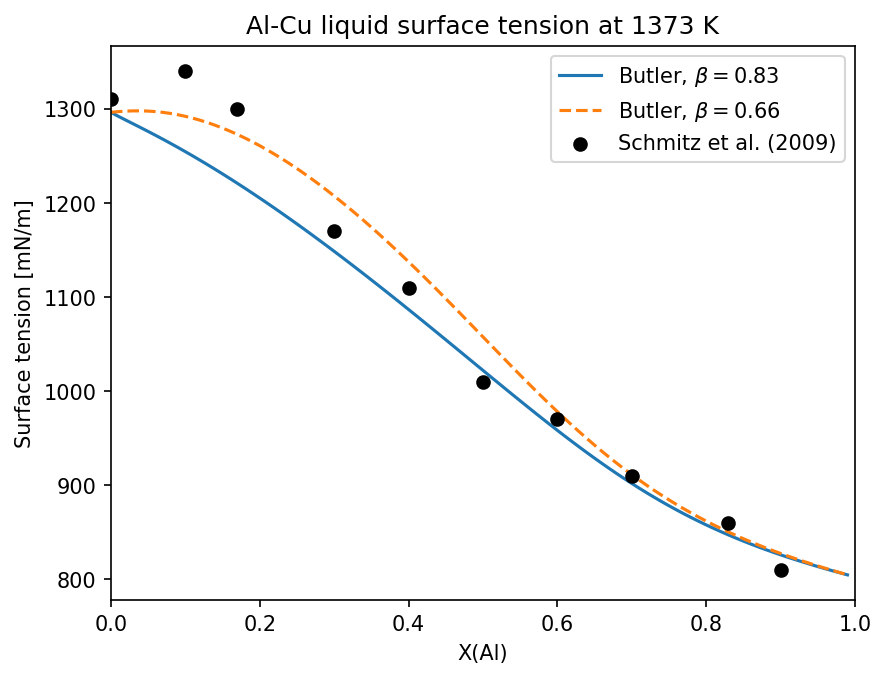

In [4]:
dbf = Database('../databases/COST507.tdb')

exp_x_al = [0.0, 0.10, 0.17, 0.30, 0.40, 0.50, 0.60, 0.70, 0.83, 0.90]
exp_sigma = [1310, 1340, 1300, 1170, 1110, 1010, 970, 910, 860, 810]  # mN/m

conditions = {v.X('AL'): (0, 1, 0.01), v.T: 1373, v.P: 101325, v.N: 1}
wks = Workspace(dbf, ['AL', 'CU', 'VA'], ['LIQUID'], conditions)
x_al, sigma_083, sigma_066 = wks.get(v.X('AL'), sigma, ButlerSurfaceTension(PURE, beta=0.66))

fig, ax = plt.subplots(dpi=150)
ax.plot(x_al, sigma_083, label=r'Butler, $\beta = 0.83$')
ax.plot(x_al, sigma_066, '--', label=r'Butler, $\beta = 0.66$')
ax.scatter(exp_x_al, exp_sigma, color='k', zorder=3, label='Schmitz et al. (2009)')
ax.set_title('Al-Cu liquid surface tension at 1373 K')
ax.set_xlabel('X(Al)')
ax.set_ylabel(f'{sigma.display_name} [{sigma.display_units}]')
ax.set_xlim(0, 1)
_ = ax.legend()

With $\beta = 0.83$ the calculation is within 2% of the measurements for `X(AL) >= 0.3` but up to 6% low on the Cu-rich side, where $\beta = 0.66$ is closer (within 4%) at the expense of the middle of the composition range. $\beta$ is the main assumption of the model; $\beta = 0.83$ is used below.

## Ternary: Al-Cu-Si

A grid over two mole fractions gives the surface tension across the ternary liquid. Grid points with `X(CU) + X(SI) > 1` have no solution and are dropped before plotting on triangular axes.

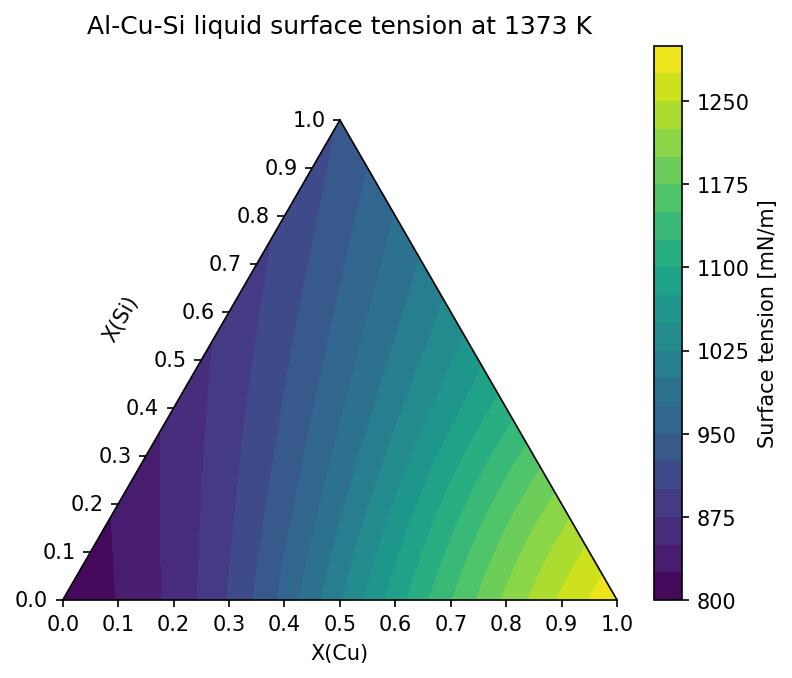

In [5]:
conditions = {v.X('CU'): np.linspace(0, 1, 41), v.X('SI'): np.linspace(0, 1, 41), v.T: 1373, v.P: 101325, v.N: 1}
wks = Workspace(dbf, ['AL', 'CU', 'SI', 'VA'], ['LIQUID'], conditions)
x_cu, x_si, sigma_values = (arr.ravel() for arr in wks.get(v.X('CU'), v.X('SI'), sigma))
valid = np.isfinite(sigma_values)

fig = plt.figure(dpi=150)
ax = fig.add_subplot(projection='triangular')
contours = ax.tricontourf(x_cu[valid], x_si[valid], sigma_values[valid], levels=20)
ax.set_title('Al-Cu-Si liquid surface tension at 1373 K')
ax.set_xlabel('X(Cu)')
ax.set_ylabel('X(Si)')
ax.yaxis.label.set_rotation(60)
ax.yaxis.set_label_coords(x=0.12, y=0.5)
_ = fig.colorbar(contours, ax=ax, label=f'{sigma.display_name} [{sigma.display_units}]')

## Multicomponent: AlSi7Cu3Mg casting alloy

For a point calculation with all phases, the surface tension is computed for the equilibrium liquid. At 850 K an Al-7Si-3.5Cu-0.4Mg (mass fraction) alloy is partly solidified, so the liquid is enriched in the solutes. The surface composition from `solve` shows that Mg segregates strongly to the surface while Cu is depleted.

In [6]:
conditions = v.get_mole_fractions({v.W('SI'): 0.07, v.W('CU'): 0.035, v.W('MG'): 0.004}, 'AL', dbf)
conditions.update({v.T: 850, v.P: 101325, v.N: 1})
wks = Workspace(dbf, ['AL', 'CU', 'MG', 'SI', 'VA'], list(dbf.phases.keys()), conditions)

print({str(k): round(float(val), 3) for k, val in wks.get_dict('NP(*)').items() if val > 0})
print(f"{sigma.display_name}: {wks.get(sigma):.0f} {sigma.display_units}")

liquid = next(cs for cs in wks.get_composition_sets() if cs.phase_record.phase_name == 'LIQUID')
_, x_surface = sigma.solve(liquid)
for y, x_b, x_s in zip(liquid.phase_record.variables, liquid.dof[liquid.phase_record.num_statevars:], x_surface):
    print(f'X({y.species}): bulk {x_b:.4f}, surface {x_s:.4f}')

{'NP_FCC_A1': 0.353, 'NP_LIQUID': 0.647}


Surface tension: 895 mN/m
X(AL): bulk 0.8714, surface 0.9159
X(CU): bulk 0.0222, surface 0.0007
X(MG): bulk 0.0065, surface 0.0429
X(SI): bulk 0.0999, surface 0.0405


Removing the solid phases gives the (undercooled) liquid at the nominal alloy composition instead.

In [7]:
wks.phases = ['LIQUID']
print(f"{sigma.display_name}: {wks.get(sigma):.0f} {sigma.display_units}")

Surface tension: 890 mN/m
